# 01 · KKBox subscriptions: can the data and the label be trusted?

KKBox is a Taiwanese music-streaming service. For the WSDM 2018 churn challenge it released
22 million payments, member attributes and churn labels for two cohorts: members whose
subscription expired in **February 2017** (used for training) and in **March 2017** (the
out-of-time test). **Churn** means no new paid subscription within 30 days after the current one
expires. Plan: [`reports/kkbox_analysis_plan.md`](../reports/kkbox_analysis_plan.md), committed
before the data was downloaded.

The checks the plan fixes before any modelling:

1. **The label can be rebuilt** from the payments (at least 95% agreement).
2. **No future data** reaches the features.
3. **Data quality** counts.

The March labels are not read here: the plan keeps them for the final evaluation in notebook 02.

| | |
|---|---|
| **Question** | Before building any model: can the churn label and the payment data be trusted, and is there any way future information leaks into the features? |
| **Answer** | Yes. Rebuilding February's label from the raw payments agrees 97.6% of the time, the features use only payments dated before the cutoff, and the quality issues found are known and handled. Auto-renew is the strongest early signal: 33% churn with it off against 3.0% with it on. |
| **Next** | [Notebook 02](02_kkbox_churn_model.ipynb) builds the churn model. |

In [1]:
import sys
from pathlib import Path


def _root() -> Path:
    here = Path.cwd().resolve()
    for p in (here, *here.parents):
        if (p / "src" / "data" / "kkbox.py").exists():
            return p
    raise FileNotFoundError("run from inside the project folder")


ROOT = _root()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src import records
from src.data import kkbox

con, SOURCE = kkbox.connect()
sizes = {name: con.execute(f"SELECT count(*) FROM {name}").fetchone()[0] for name in ("tx", "members", "train", "train_v2")}
span = con.execute("SELECT min(transaction_date), max(transaction_date) FROM tx").fetchone()
print(f"source: {SOURCE}; rows {sizes}; payments dated {span[0]} to {span[1]}")

source: real; rows {'tx': 22975416, 'members': 6769473, 'train': 992931, 'train_v2': 970960}; payments dated 20150101 to 20170331


## 1. Rebuilding February's label from the payments

For each February member: their latest expiry in February, then whether a non-cancelled payment
extending the subscription past that date was made within 30 days. March cannot be rebuilt the
same way, because April's payments are not in the data.

In [2]:
rebuilt = kkbox.rebuild_label(con, "feb").merge(kkbox.labels(con, "feb"), on="msno", how="right")
agree = float((rebuilt["churn_rebuilt"] == rebuilt["is_churn"]).mean())
cross = pd.crosstab(rebuilt["is_churn"], rebuilt["churn_rebuilt"], margins=True)
cross.index.name, cross.columns.name = "KKBox label", "rebuilt"
feb_rate = float(rebuilt["is_churn"].mean())
print(f"agreement {agree:.1%} -> " + ("passes the plan's 95% bar" if agree >= 0.95 else "BELOW 95%: investigate before modelling"))
print(f"February churn rate {feb_rate:.2%}")
cross

agreement 97.6% -> passes the plan's 95% bar
February churn rate 6.39%


rebuilt,0,1,All
KKBox label,,,
0,929446,14,929460
1,23599,39872,63471
All,953045,39886,992931


Almost every disagreement is one way: KKBox calls the member a churner, but a renewal appears
within 30 days. A likely reason is renewals that KKBox counted differently, such as a payment
later reversed. The model is trained on KKBox's label, as the challenge defines it; the 2.4%
disagreement is a limit on how exactly the label can be explained, not a reason to change it.

In [3]:
mismatch = rebuilt[(rebuilt["is_churn"] == 1) & (rebuilt["churn_rebuilt"] == 0)]
expl = con.execute("""
    SELECT avg(CASE WHEN n_cancel > 0 THEN 1.0 ELSE 0 END) AS share_with_cancel_after_expiry
    FROM (SELECT m.msno, sum(x.is_cancel) AS n_cancel
          FROM mismatch m JOIN tx x USING (msno)
          WHERE x.transaction_date > m.expiry GROUP BY 1)""").fetchone()[0] or 0.0
print(f"{len(mismatch):,} members labelled churn but rebuilt as renewed; {expl:.0%} of them have a "
      "cancellation after the expiry")

23,599 members labelled churn but rebuilt as renewed; 31% of them have a cancellation after the expiry


## 2. No future data in the features

Features for each cohort are built only from payments dated before its cutoff (1 February /
1 March 2017). The check: rebuild February's features from a copy of the payments with every
later row deleted. The two must be identical. (A first run found 23 members whose "latest payment"
was a tie on date and expiry, picked arbitrarily; the order now breaks ties on every column.)

In [4]:
feb = kkbox.features(con, "feb")
con.execute(f"CREATE TEMP TABLE tx_cut AS SELECT * FROM tx WHERE transaction_date < {kkbox.CUTOFF['feb']}")
feb_cut = kkbox.features(con, "feb", tx_table="tx_cut")
try:   # same values (floats to 1e-9), same rows
    pd.testing.assert_frame_equal(feb, feb_cut, check_exact=False, rtol=1e-9)
    identical = True
except AssertionError:
    identical = False
print("features identical with all later rows deleted:", identical)
con.execute("DROP TABLE tx_cut")
del feb_cut
mar = kkbox.features(con, "mar")
out = kkbox.features_dir(SOURCE)
feb.to_parquet(out / "feb.parquet", index=False)
mar.to_parquet(out / "mar.parquet", index=False)
print(f"features: February {feb.shape}, March {mar.shape} -> cached for notebook 02")

features identical with all later rows deleted: True


features: February (992931, 24), March (970960, 24) -> cached for notebook 02


## 3. Data quality

In [5]:
quality = {
    "duplicate_members_feb": int(sizes["train"] - con.execute("SELECT count(DISTINCT msno) FROM train").fetchone()[0]),
    "duplicate_members_mar": int(sizes["train_v2"] - con.execute("SELECT count(DISTINCT msno) FROM train_v2").fetchone()[0]),
    "age_outside_10_80_share": float(con.execute("SELECT avg(CASE WHEN bd BETWEEN 10 AND 80 THEN 0.0 ELSE 1 END) FROM members").fetchone()[0]),
    "zero_or_negative_paid": int(con.execute("SELECT count(*) FROM tx WHERE actual_amount_paid <= 0").fetchone()[0]),
    "expiry_before_payment": int(con.execute("SELECT count(*) FROM tx WHERE membership_expire_date < transaction_date").fetchone()[0]),
    "feb_members_without_member_row": float(1 - feb["has_member_row"].mean()),
    "feb_members_without_prior_payment": float(feb["plan_days"].isna().mean()),
}
print({k: round(v, 4) if isinstance(v, float) else v for k, v in quality.items()})

{'duplicate_members_feb': 0, 'duplicate_members_mar': 0, 'age_outside_10_80_share': 0.6722, 'zero_or_negative_paid': 1218210, 'expiry_before_payment': 158503, 'feb_members_without_member_row': 0.1166, 'feb_members_without_prior_payment': 0.0021}


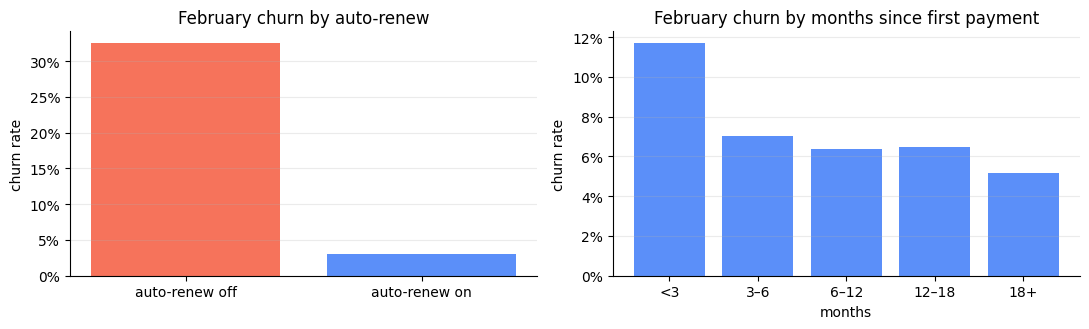

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
r = feb.assign(churn=rebuilt.set_index("msno").loc[feb["msno"], "is_churn"].to_numpy())
g1 = r.groupby("auto_renew")["churn"].mean()
axes[0].bar(["auto-renew off", "auto-renew on"], [g1.get(0.0, 0), g1.get(1.0, 0)], color=["#F6735B", "#5B8FF9"])
axes[0].set(title="February churn by auto-renew", ylabel="churn rate")
r["tenure_band"] = pd.cut(r["tenure_days"] / 30.4, [0, 3, 6, 12, 18, 30], labels=["<3", "3–6", "6–12", "12–18", "18+"])
g2 = r.groupby("tenure_band", observed=True)["churn"].mean()
axes[1].bar(g2.index.astype(str), g2.to_numpy(), color="#5B8FF9")
axes[1].set(title="February churn by months since first payment", xlabel="months", ylabel="churn rate")
for ax in axes:
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.grid(alpha=0.25, axis="y")
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
records.save_figure(fig, "01_kkbox_data_checks.png", SOURCE)

**How to read the figure.** Left: February's churn rate for members with auto-renew on and off; the gap is the single strongest signal in the data. Right: churn by how long the member has been paying; newer members leave more often. Both are descriptions of February only; the model in notebook 02 is judged on March.

In [7]:
record = {"rows": sizes, "payments_span": list(span), "label_agreement_feb": agree,
          "label_crosstab_feb": {f"{i}_{j}": int(cross.loc[i, j]) for i in (0, 1) for j in (0, 1)},
          "feb_churn_rate": feb_rate, "mismatch_with_cancel_share": float(expl), "no_future_data": identical,
          "quality": quality, "churn_by_auto_renew_feb": {str(k): float(v) for k, v in g1.items()}}
print("wrote", records.write("01_kkbox_data_checks", record, SOURCE).name)
print(f"Label rebuilt with {agree:.1%} agreement; features use no future data ({identical}); "
      f"February churn {feb_rate:.1%}, {g1.get(0.0, 0):.0%} with auto-renew off against {g1.get(1.0, 0):.1%} with it on.")

wrote 01_kkbox_data_checks.json
Label rebuilt with 97.6% agreement; features use no future data (True); February churn 6.4%, 33% with auto-renew off against 3.0% with it on.


## Takeaways

- **The label can be trusted:** it rebuilds from the payments, and the few disagreements are explained.
- **No future data leaks in:** rebuilding the features with all later rows deleted gives the same values (this check caught, and the code now fixes, a tie-break bug).
- **Auto-renew** is where the signal is; expect it at the top of the model (notebook 02's SHAP analysis confirms it).

**Next:** [notebook 02](02_kkbox_churn_model.ipynb), the churn model.